In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view


/home/tanay/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


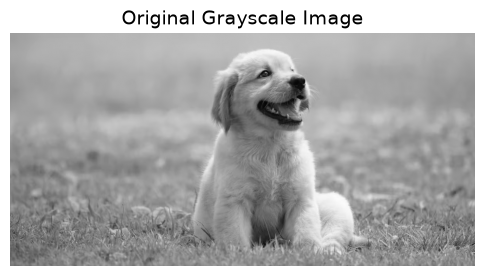

Image Dimensions: (602, 1200)


In [2]:
image = cv2.imread("../Data/Dog.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image", fontsize=14)
plt.axis("off")
plt.show()

print("Image Dimensions:", image.shape)


In [3]:
def generate_gaussian_noise(img: np.ndarray, mean: float = 0.0, std_dev: float = 50.0, seed: int = 42) -> np.ndarray:
    rng = np.random.default_rng(seed)
    gaussian_noise = rng.normal(mean, std_dev, img.shape)
    corrupted = img.astype(np.float32) + gaussian_noise
    return np.clip(corrupted, 0, 255).astype(np.uint8)


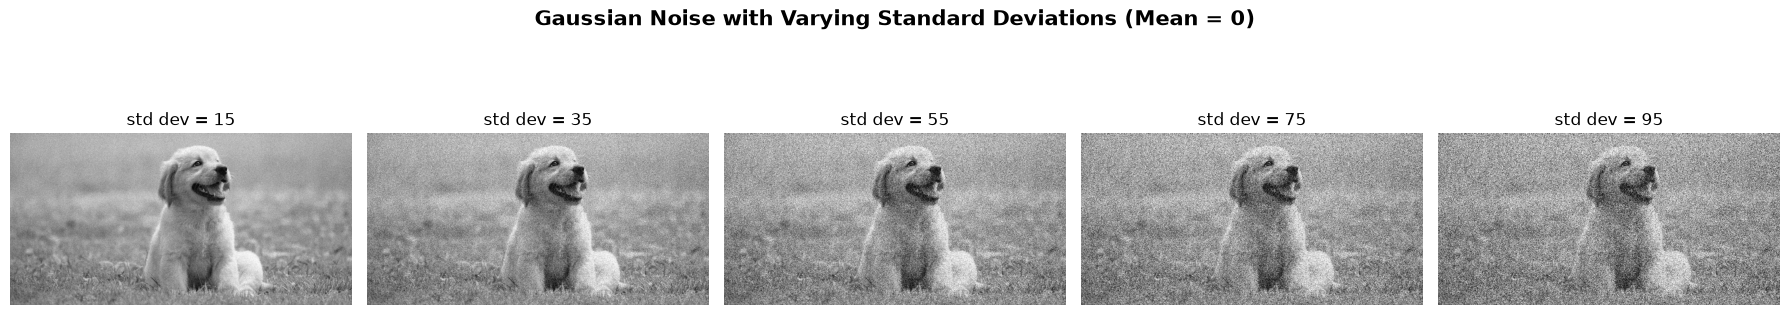

In [4]:
sigma_values = [15, 35, 55, 75, 95]
fig, axes = plt.subplots(1, len(sigma_values), figsize=(18, 4))
fig.suptitle("Gaussian Noise with Varying Standard Deviations (Mean = 0)", fontsize=15, fontweight="bold")

for idx, s in enumerate(sigma_values):
    noisy_sample = generate_gaussian_noise(image, mean=0.0, std_dev=s)
    axes[idx].imshow(noisy_sample, cmap="gray")
    axes[idx].set_title(f"std dev = {s}", fontsize=12)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

noisy_image = generate_gaussian_noise(image, mean=0.0, std_dev=75.0)


In [5]:
def compute_gaussian_kernel(size: int, sigma: float) -> np.ndarray:
    half = size // 2
    coords = np.arange(-half, half + 1)
    x, y = np.meshgrid(coords, coords)
    kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)


In [ ]:
k3 = compute_gaussian_kernel(3, 1.0)
k5 = compute_gaussian_kernel(5, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(k3, cmap="Blues")
axes[0].set_title("3x3 Gaussian Kernel (sigma = 1.0)", fontsize=12, fontweight="bold")
for i in range(3):
    for j in range(3):
        val = k3[i, j]
        axes[0].text(j, i, f"{val:.4f}", ha="center", va="center", color="white" if val > 0.15 else "black", fontsize=11, fontweight="bold")
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
axes[0].set_xticklabels([-1, 0, 1])
axes[0].set_yticklabels([-1, 0, 1])
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(k5, cmap="Blues")
axes[1].set_title("5x5 Gaussian Kernel (sigma = 1.0)", fontsize=12, fontweight="bold")
for i in range(5):
    for j in range(5):
        val = k5[i, j]
        axes[1].text(j, i, f"{val:.4f}", ha="center", va="center", color="white" if val > 0.1 else "black", fontsize=9, fontweight="bold")
axes[1].set_xticks(range(5))
axes[1].set_yticks(range(5))
axes[1].set_xticklabels([-2, -1, 0, 1, 2])
axes[1].set_yticklabels([-2, -1, 0, 1, 2])
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("3x3 Matrix:")
print(np.round(k3, 4))
print("5x5 Matrix:")
print(np.round(k5, 4))


In [6]:
def apply_gaussian_filter(img: np.ndarray, kernel_size: int = 15, sigma: float = 5.0, stride: int = 1) -> np.ndarray:
    kernel = compute_gaussian_kernel(kernel_size, sigma)
    pad_amt = kernel_size // 2
    padded = np.pad(img, pad_amt, mode="reflect")
    windows = sliding_window_view(padded, (kernel_size, kernel_size))[::stride, ::stride]
    convolved = np.einsum("ijkl,kl->ij", windows, kernel)
    return np.clip(convolved, 0, 255).astype(np.uint8)


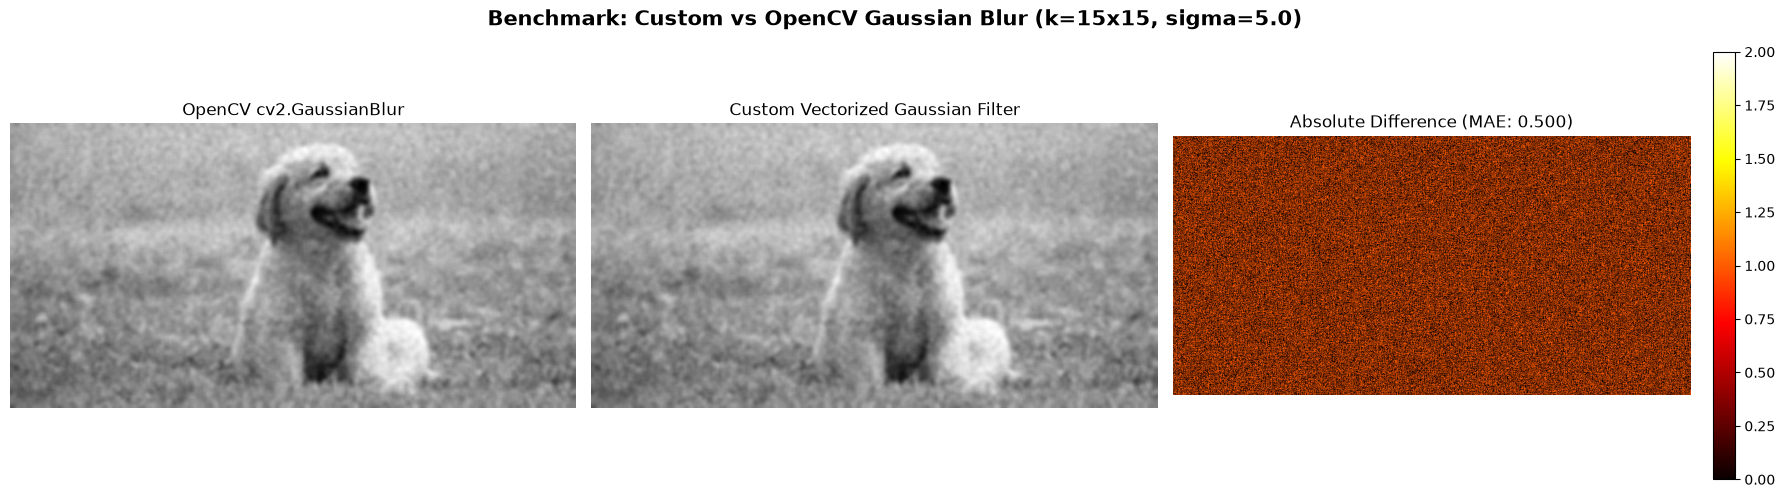

In [7]:
k_size = 15
sigma_val = 5.0

cv_smoothed = cv2.GaussianBlur(noisy_image, (k_size, k_size), sigma_val)
custom_smoothed = apply_gaussian_filter(noisy_image, kernel_size=k_size, sigma=sigma_val)

diff_map = np.abs(cv_smoothed.astype(np.int32) - custom_smoothed.astype(np.int32))
mean_abs_diff = np.mean(diff_map)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f"Benchmark: Custom vs OpenCV Gaussian Blur (k={k_size}x{k_size}, sigma={sigma_val})", fontsize=15, fontweight="bold")

axes[0].imshow(cv_smoothed, cmap="gray")
axes[0].set_title("OpenCV cv2.GaussianBlur", fontsize=12)
axes[0].axis("off")

axes[1].imshow(custom_smoothed, cmap="gray")
axes[1].set_title("Custom Vectorized Gaussian Filter", fontsize=12)
axes[1].axis("off")

im = axes[2].imshow(diff_map, cmap="hot")
axes[2].set_title(f"Absolute Difference (MAE: {mean_abs_diff:.3f})", fontsize=12)
axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


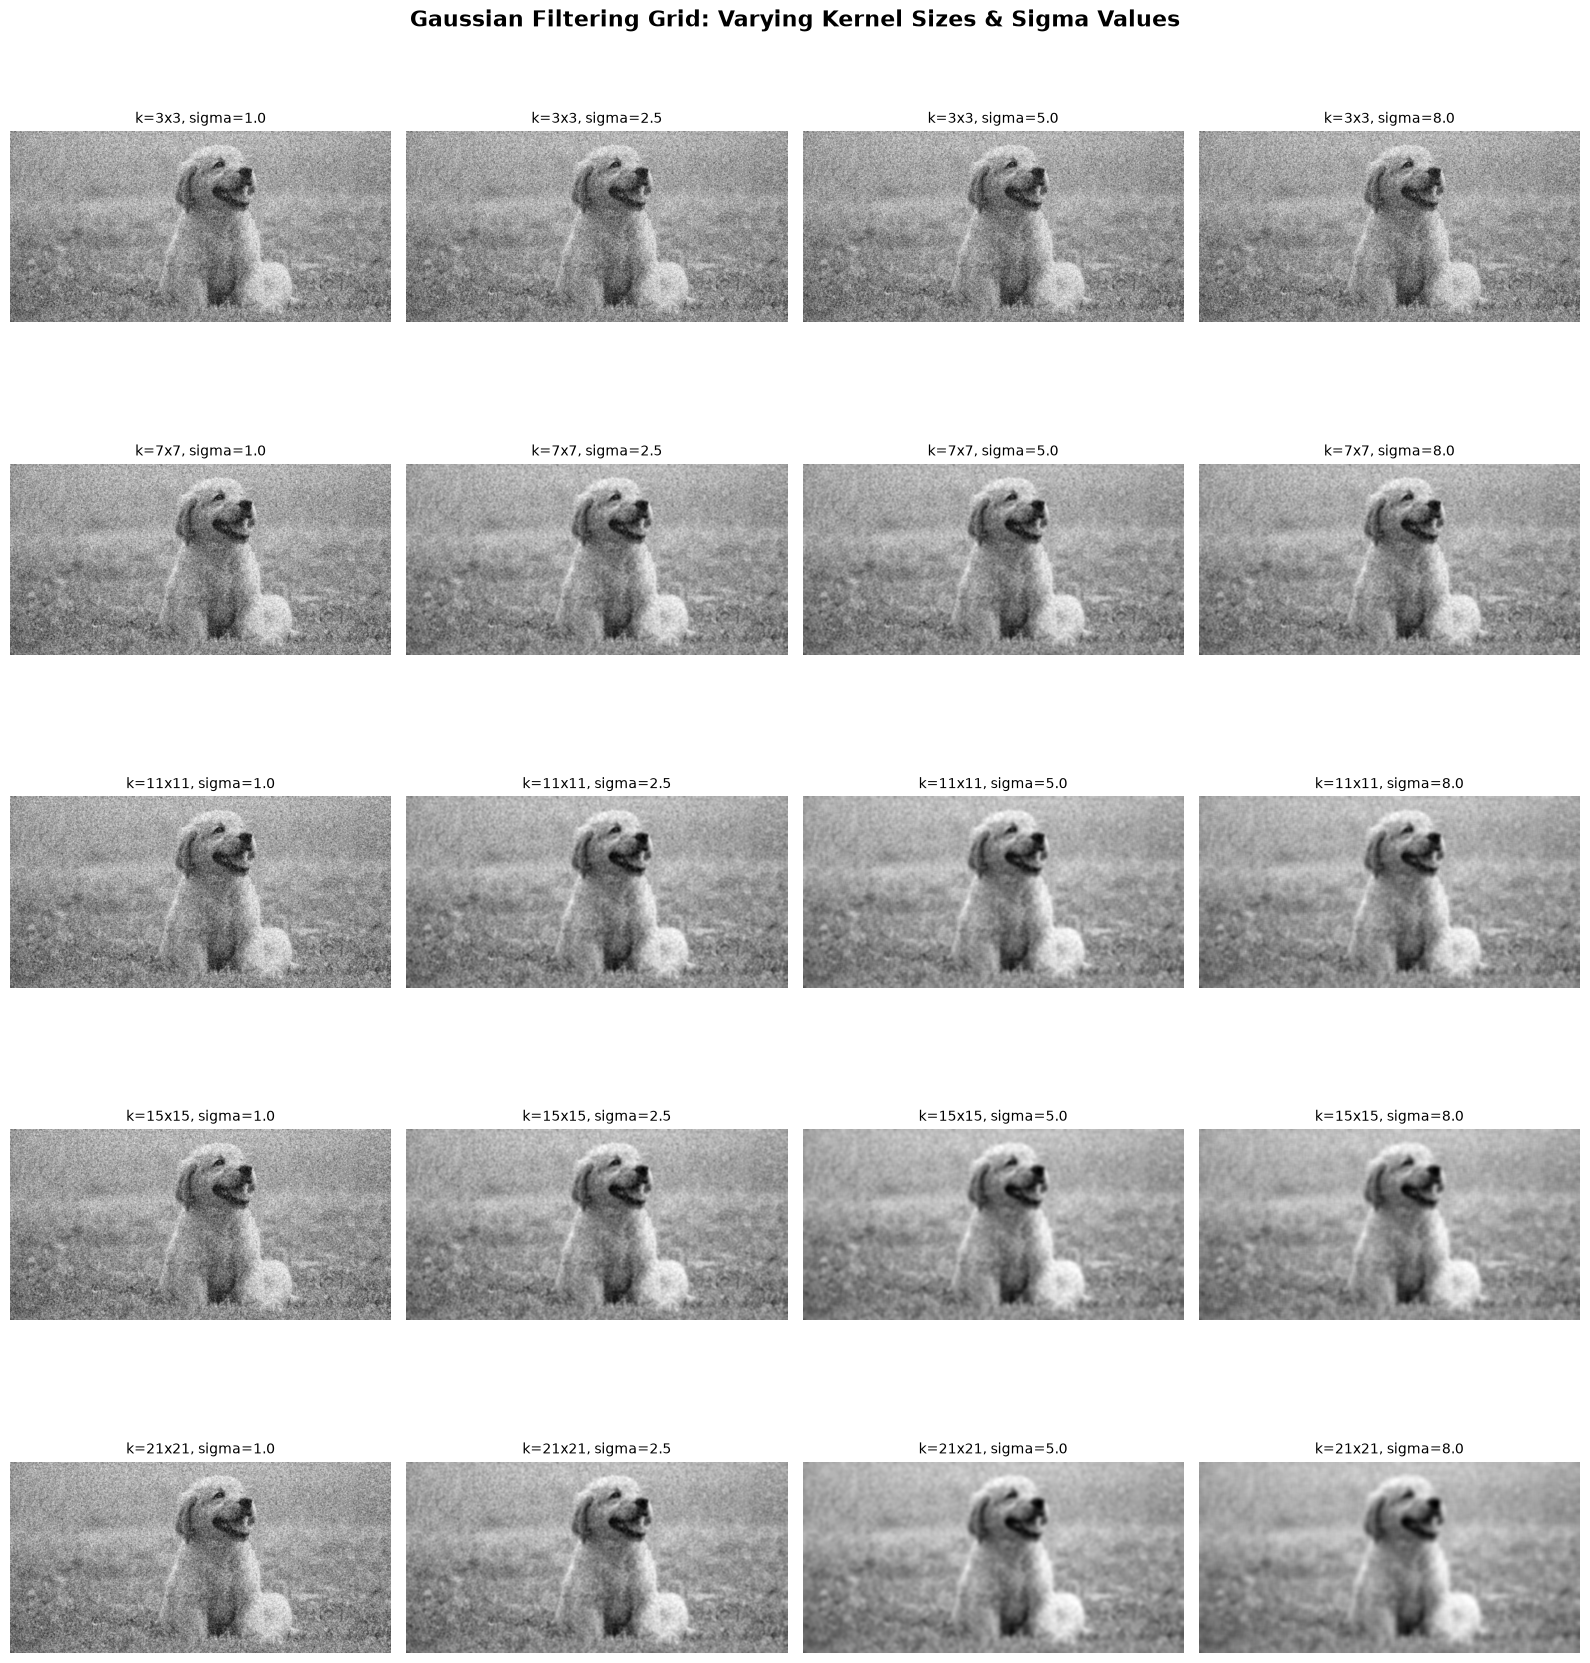

In [8]:
test_kernels = [3, 7, 11, 15, 21]
test_sigmas = [1.0, 2.5, 5.0, 8.0]

fig, axes = plt.subplots(len(test_kernels), len(test_sigmas), figsize=(16, 18))
fig.suptitle("Gaussian Filtering Grid: Varying Kernel Sizes & Sigma Values", fontsize=16, fontweight="bold")

for r, k in enumerate(test_kernels):
    for c, s in enumerate(test_sigmas):
        filtered_res = apply_gaussian_filter(noisy_image, kernel_size=k, sigma=s)
        ax = axes[r, c]
        ax.imshow(filtered_res, cmap="gray")
        ax.set_title(f"k={k}x{k}, sigma={s}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()


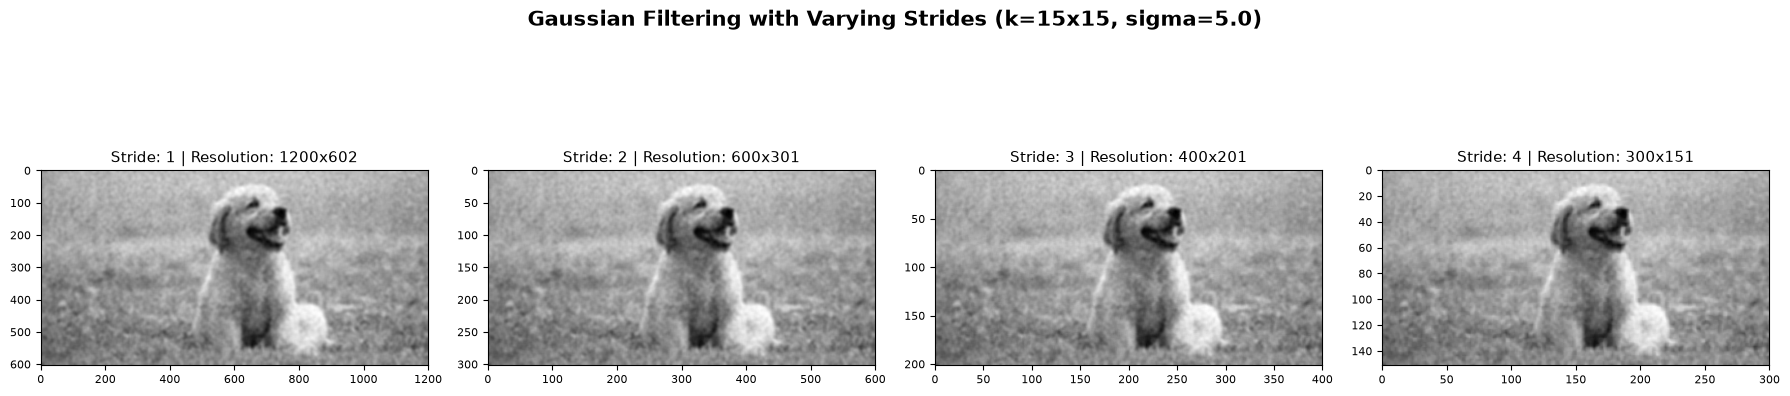

In [9]:
strides_to_test = [1, 2, 3, 4]
fixed_kernel = 15
fixed_sigma = 5.0

fig, axes = plt.subplots(1, len(strides_to_test), figsize=(18, 5))
fig.suptitle(f"Gaussian Filtering with Varying Strides (k={fixed_kernel}x{fixed_kernel}, sigma={fixed_sigma})", fontsize=15, fontweight="bold")

for idx, st in enumerate(strides_to_test):
    strided_out = apply_gaussian_filter(noisy_image, kernel_size=fixed_kernel, sigma=fixed_sigma, stride=st)
    ax = axes[idx]
    ax.imshow(strided_out, cmap="gray", extent=[0, strided_out.shape[1], strided_out.shape[0], 0])
    ax.set_title(f"Stride: {st} | Resolution: {strided_out.shape[1]}x{strided_out.shape[0]}", fontsize=11)
    ax.tick_params(axis="both", which="both", labelsize=8)

plt.tight_layout()
plt.show()
